Found 156 files belonging to 5 classes.


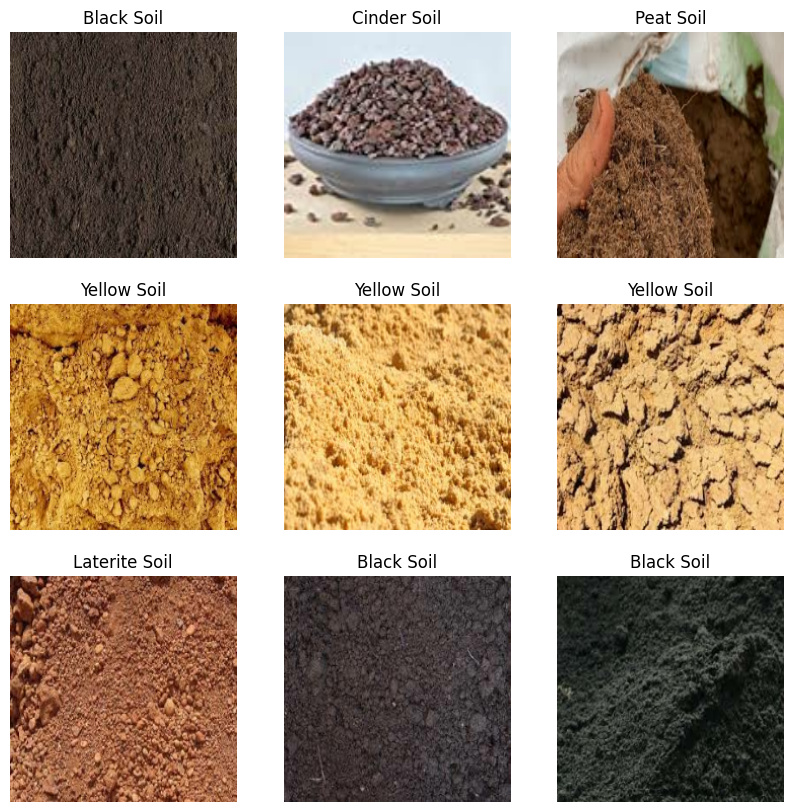

In [ ]:
import tensorflow as tf

# Load dataset as a tf.data.Dataset
dataset = tf.keras.utils.image_dataset_from_directory(
    r"E:\126156068\soil\Soil types",
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(224, 224),
    shuffle=True,
    seed=42
)

# Visualize first batch
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
for images, labels in dataset.take(1):
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(dataset.class_names[tf.argmax(labels[i])])
        plt.axis('off')
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import os

data = []
labels = []
class_names = sorted(os.listdir(r"E:\126156068\soil\Soil types"))

for class_name in class_names:
    class_dir = os.path.join(r"E:\126156068\soil\Soil types", class_name)
    for img_name in os.listdir(class_dir):
        img_path = os.path.join(class_dir, img_name)
        img = load_img(img_path, target_size=(224, 224))
        img_array = img_to_array(img)
        data.append(img_array)
        labels.append(class_names.index(class_name))

# Convert to numpy arrays
import numpy as np
data = np.array(data)
labels = np.array(labels)

print(f"Data shape: {data.shape}, Labels shape: {labels.shape}")

Data shape: (156, 224, 224, 3), Labels shape: (156,)


In [ ]:
import cv2
import os
import numpy as np

data = []
labels = []
class_names = sorted(os.listdir(r"E:\126156068\soil\Soil types"))

for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(r"E:\126156068\soil\Soil types", class_name)
    for img_name in os.listdir(class_dir):
        img_path = os.path.join(class_dir, img_name)
        img = cv2.imread(img_path)
        img = cv2.resize(img, (224, 224))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
        data.append(img)
        labels.append(class_idx)

data = np.array(data)
labels = np.array(labels)
print(f"OpenCV loaded {len(data)} images.")

OpenCV loaded 156 images.


In [ ]:
from PIL import Image
import os
import numpy as np

data = []
labels = []
class_names = sorted(os.listdir(r"E:\126156068\soil\Soil types"))

for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(r"E:\126156068\soil\Soil types", class_name)
    for img_name in os.listdir(class_dir):
        img_path = os.path.join(class_dir, img_name)
        img = Image.open(img_path).convert('RGB')
        img = img.resize((224, 224))
        img_array = np.array(img)
        data.append(img_array)
        labels.append(class_idx)

data = np.array(data)
labels = np.array(labels)
print(f"PIL loaded {len(data)} images.")

PIL loaded 156 images.


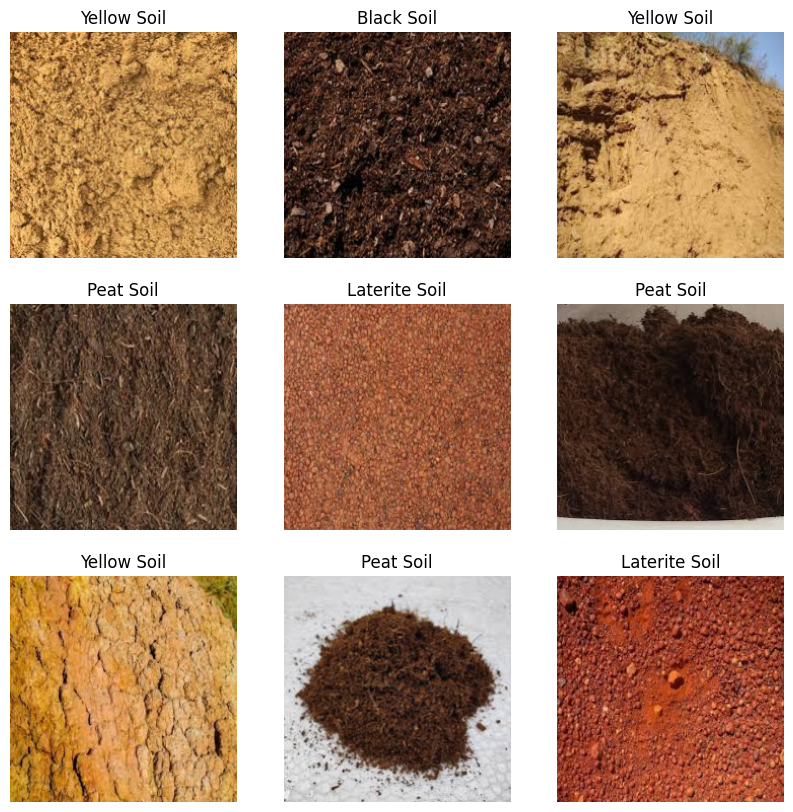

In [ ]:
import torch
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

dataset = datasets.ImageFolder(
    root=r"E:\126156068\soil\Soil types",
    transform=transform
)

dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

# Visualize first batch
import matplotlib.pyplot as plt
batch = next(iter(dataloader))
images, labels = batch
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i].permute(1, 2, 0))  # CHW to HWC
    plt.title(dataset.classes[labels[i]])
    plt.axis('off')
plt.show()

In [ ]:
import tensorflow as tf
import numpy as np

class CustomDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, dir_path, batch_size=32, img_size=(224, 224)):
        self.dir_path = dir_path
        self.batch_size = batch_size
        self.img_size = img_size
        self.class_names = sorted(os.listdir(dir_path))
        self.file_paths = []
        self.labels = []

        for class_idx, class_name in enumerate(self.class_names):
            class_dir = os.path.join(dir_path, class_name)
            for img_name in os.listdir(class_dir):
                self.file_paths.append(os.path.join(class_dir, img_name))
                self.labels.append(class_idx)

    def __len__(self):
        return int(np.ceil(len(self.file_paths) / self.batch_size))

    def __getitem__(self, idx):
        batch_files = self.file_paths[idx*self.batch_size:(idx+1)*self.batch_size]
        batch_labels = self.labels[idx*self.batch_size:(idx+1)*self.batch_size]

        batch_images = []
        for file_path in batch_files:
            img = tf.keras.preprocessing.image.load_img(file_path, target_size=self.img_size)
            img_array = tf.keras.preprocessing.image.img_to_array(img)
            batch_images.append(img_array)

        return np.array(batch_images), tf.keras.utils.to_categorical(batch_labels, num_classes=len(self.class_names))

# Usage
train_generator = CustomDataGenerator(r"E:\126156068\soil\Soil types")
print(f"Total batches: {len(train_generator)}")

Total batches: 5
